In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

color_pal = sns.color_palette()
plt.style.use('fivethirtyeight')

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings("ignore")

**Quartely Data loading and Setup**


In [ ]:
df = pd.read_csv('/content/Monthly_data_new.csv')

df = df.set_index('Date')
df.index = pd.to_datetime(df.index)



In [ ]:
df = df.iloc[2:]

In [ ]:
for col in df.columns:
    if df[col].dtype == 'object':
        # Remove commas and convert to float
        df[col] = pd.to_numeric(df[col].str.replace(',', ''), errors='coerce')


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
Columns_for_GDP = ['Total CPI, Percentage Change over 1 year ago (unadjusted)',
                   'Target Rate (Percent)',
                   'Oil WTI',
                   'Brent_Europe',
                   'Real Exchange rate']


df_ML = df.copy()
df_ML.columns = df_ML.columns.str.strip()
df_ML = df_ML[Columns_for_GDP]

In [ ]:
df_YoY = df_ML.copy()

Col_YoY = [
           ]

Target = 'Total CPI, Percentage Change over 1 year ago (unadjusted)'

Features = df_ML.drop(Target, axis=1).columns

df_YoY = df_YoY[Col_YoY]

In [ ]:
for col in df_YoY.columns:
    df_YoY[col] = df_YoY[col].pct_change(4) * 100
    df_ML.drop(col, axis=1, inplace=True)


In [ ]:
df_ML = df_ML.join(df_YoY, how='left')


In [ ]:
df_ML['Total CPI, Percentage Change over 1 year ago (unadjusted)'].tail(76)

,"Total CPI, Percentage Change over 1 year ago (unadjusted)"
Date,
2020-01-01,2.4
2020-02-01,2.2
2020-03-01,0.9
2020-04-01,-0.2
2020-05-01,-0.4
...,...
NaT,NaN
NaT,NaN
NaT,NaN


Lag

In [ ]:
def create_lags(df):
    """
    Creates lagged features for GDP and exogenous predictors.
    Adds time index and quarter number for seasonal/trend info.
    """
    df2 = df.copy()

    # GDP lags
    for col in df2.columns:
        for i in range(1,13):
            df2[f'{col}_lag{i}'] = df2[col].shift(i)

    df2['month'] = df2.index.month
    df2['time_index'] = np.arange(len(df2))

    # Drop rows with NaNs caused by lags
    df2.dropna(inplace=True)
    return df2


In [ ]:
df_features = create_lags(df_ML)

Model

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor


X = df_features.drop(Target, axis=1)
y = df_features[Target]

In [ ]:
split = int(0.8 * len(df_features))
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

In [ ]:
model = XGBRegressor(
    n_estimators=1000,
    max_depth=5, # From best_params
    learning_rate=0.1, # From best_params
    subsample=0.7, # From best_params
    colsample_bytree=1.0, # From best_params
    random_state=42,
    eval_metric="rmse",
    early_stopping_rounds=20,
)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

model.fit(X_train, y_train,
          eval_set=[(X_test, y_test)],
          verbose=False)

y_pred = model.predict(X_test)


# Mean Squared Error
mae = mean_absolute_error(y_test, y_pred)
# Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
# Root Mean Squared Error
rmse = np.sqrt(mse)
# R-squared
r2 = r2_score(y_test, y_pred)

print(f'Test MAE: {mae:.4f}')
print(f'Test MSE: {mse:.4f}')
print(f'Test RMSE: {rmse:.4f}')
print(f'Test R²: {r2:.4f}')

Test MAE: 1.3264
Test MSE: 3.8871
Test RMSE: 1.9716
Test R²: 0.1011


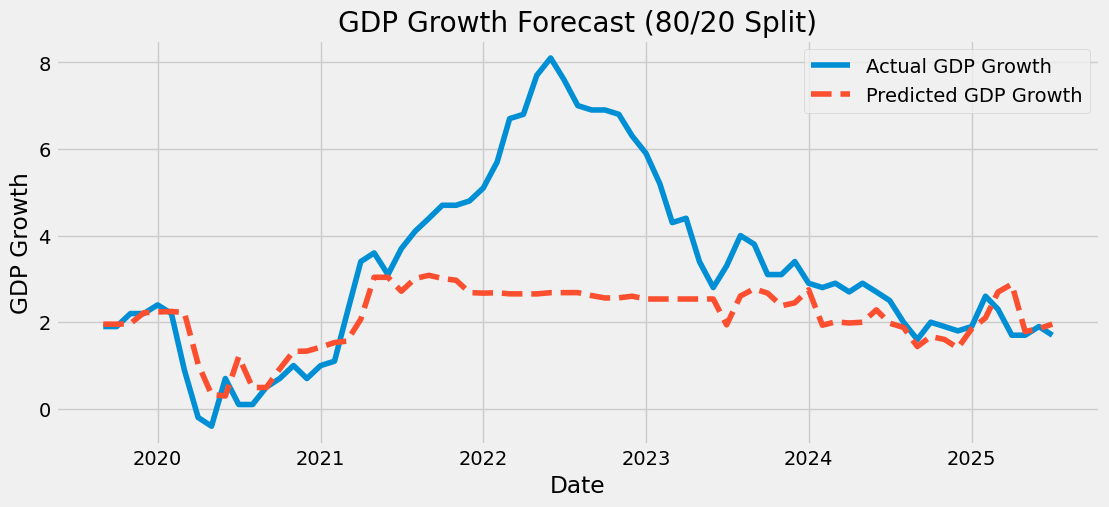

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(y_test.index, y_test, label='Actual GDP Growth')
plt.plot(y_test.index, y_pred, label='Predicted GDP Growth', linestyle='--')
plt.title('GDP Growth Forecast (80/20 Split)')
plt.xlabel('Date')
plt.ylabel('GDP Growth')
plt.legend()
plt.grid(True)
plt.show()


TimeSeriesSplit Cross Validation

In [ ]:
# TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

mae_list, mse_list, rmse_list, r2_list = [], [], [], []

# To store all predictions for plotting
all_preds = pd.Series(index=y.index, dtype=float)

for fold, (train_index, test_index) in enumerate(tscv.split(X), 1):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    model.fit(X_train, y_train,
          eval_set=[(X_test, y_test)],
          verbose=False)

    y_pred = model.predict(X_test)

    # Save predictions for plotting
    all_preds.iloc[test_index] = y_pred

    # Metrics
    mae_list.append(mean_absolute_error(y_test, y_pred))
    mse_list.append(mean_squared_error(y_test, y_pred))
    rmse_list.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    r2_list.append(r2_score(y_test, y_pred))

    print(f"Fold {fold}: MAE={mae_list[-1]:.4f}, RMSE={rmse_list[-1]:.4f}, R²={r2_list[-1]:.4f}")

print("\nAverage metrics across folds:")
print(f"MAE: {np.mean(mae_list):.4f}")
print(f"MSE: {np.mean(mse_list):.4f}")
print(f"RMSE: {np.mean(rmse_list):.4f}")
print(f"R²: {np.mean(r2_list):.4f}")

Fold 1: MAE=0.5311, RMSE=0.6877, R²=0.4391
Fold 2: MAE=0.5966, RMSE=0.8672, R²=0.2099
Fold 3: MAE=0.3766, RMSE=0.4579, R²=0.6858
Fold 4: MAE=0.3096, RMSE=0.4069, R²=0.6233
Fold 5: MAE=1.4948, RMSE=2.1517, R²=-0.1696

Average metrics across folds:
MAE: 0.6617
MSE: 1.2460
RMSE: 0.9143
R²: 0.3577


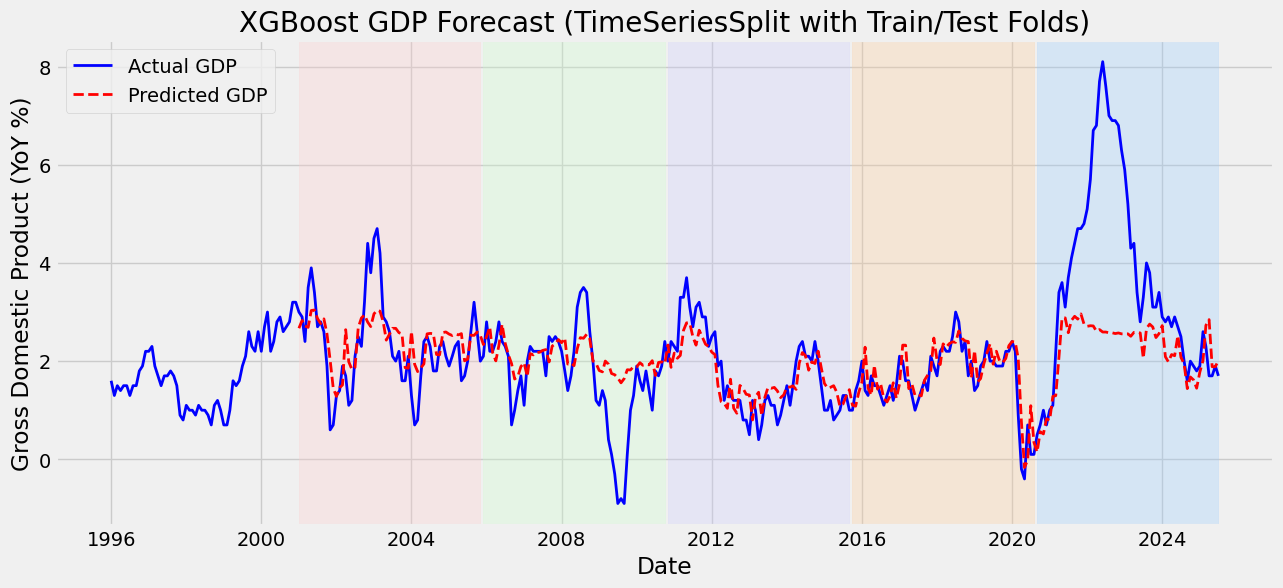

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Assuming X, y, df_features are already defined

#model = XGBRegressor(
    #n_estimators=200,
    #max_depth=3,
    #learning_rate=0.1,
    #random_state=42
#)

#XGBRegressor(
    #n_estimators=1000,
    #max_depth=5,
    #learning_rate=0.1,
    #subsample=0.7, random_state=42
    #)

tscv = TimeSeriesSplit(n_splits=5)

all_preds = pd.Series(index=y.index, dtype=float)
fold_colors = ['#FFCCCC', '#CCFFCC', '#CCCCFF', '#FFCC99', '#99CCFF']  # different color for each test fold

plt.figure(figsize=(14,6))
plt.plot(y.index, y, label='Actual GDP', color='blue', linewidth=2)

for fold, (train_index, test_index) in enumerate(tscv.split(X)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    model.fit(X_train, y_train,
          eval_set=[(X_test, y_test)],
          verbose=False)
    y_pred = model.predict(X_test)

    # Save predictions for plotting
    all_preds.iloc[test_index] = y_pred

    # Highlight test period
    plt.axvspan(y.index[test_index[0]], y.index[test_index[-1]], color=fold_colors[fold], alpha=0.3)

# Plot predicted GDP
plt.plot(all_preds.index, all_preds, label='Predicted GDP', color='red', linestyle='--', linewidth=2)

plt.title('XGBoost GDP Forecast (TimeSeriesSplit with Train/Test Folds)')
plt.xlabel('Date')
plt.ylabel('Gross Domestic Product (YoY %)')
plt.legend()
plt.show()


Predicting Future

Multi-Output

In [ ]:
df_final = create_lags(df_ML)

In [ ]:
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor


targets = df_ML.columns.to_list()

# How many past lags to use for all variables
max_lag = 12


# Define features (lagged columns + optional time/seasonal)
X = df_features.drop(targets, axis=1)
y = df_features[targets]

# Wrap XGB in MultiOutputRegressor
multi_model = MultiOutputRegressor(
    XGBRegressor(n_estimators=1000, max_depth=5, learning_rate=0.1, subsample=0.7, random_state=42)
)

multi_model.fit(X, y)


MultiOutputRegressor(estimator=XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=5,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=1000, n_jobs=None,
                                            num_parallel_tree=None, ...))

In [ ]:
def forecast_multivar_single_model(multi_model, df_features, targets, max_lag=4, steps=8):
    last_row = df_features.iloc[-1].copy()
    X_cols = df_features.drop(targets, axis=1).columns
    future_preds = {t: [] for t in targets}
    last_date = df_features.index[-1]

    # Identify lag columns for each target
    lag_cols = {t: sorted([c for c in X_cols if t in c], key=lambda x: int(x.split('lag')[1])) for t in targets}

    # Store constant values
    bank_rate_col = 'Target Rate (Percent)'
    real_exchange_rate_col = 'Real Exchange rate'
    WTI_col = 'WTI'
    Brent_col = 'Brent_europe'
    constant_bank_rate = last_row[bank_rate_col] - 0.25
    constant_real_exchange = last_row[real_exchange_rate_col]
    constant_WTI = 60
    constant_Brent_eruope = 65

    # Forecast
    for step in range(steps):
        # Predict next step
        X_pred = last_row[X_cols].values.reshape(1, -1)
        y_next = multi_model.predict(X_pred)[0]

        for i, t in enumerate(targets):
            # Apply constant assumptions
            if t == bank_rate_col:
                future_preds[t].append(constant_bank_rate)
            elif t == real_exchange_rate_col:
                future_preds[t].append(constant_real_exchange)
            elif t == WTI_col:
                future_preds[t].append(constant_WTI)
            elif t == Brent_col:
                future_preds[t].append(constant_Brent_eruope)
            else:
                future_preds[t].append(y_next[i])

        # Update lag columns for next step
        for t in targets:
            if t in [bank_rate_col, real_exchange_rate_col, WTI_col, Brent_col, pop_col]:
                # Do not update these lags; keep constant
                continue
            else:
                # Update other variable lags normally
                for i in reversed(range(len(lag_cols[t]))):
                    if i == 0:
                        last_row[lag_cols[t][i]] = y_next[targets.index(t)]
                    else:
                        last_row[lag_cols[t][i]] = last_row[lag_cols[t][i-1]]

    # Create future dates
    future_dates = pd.date_range(start=last_date + pd.offsets.MonthBegin(), periods=steps, freq='MS')
    return pd.DataFrame(future_preds, index=future_dates)

In [ ]:
future_multivar = forecast_multivar_single_model(
    multi_model,
    df_features,
    targets,
    max_lag=max_lag,
    steps=24
)
print(future_multivar)

            Total CPI, Percentage Change over 1 year ago (unadjusted)  \
2025-08-01                                           1.700050           
2025-09-01                                           1.967795           
2025-10-01                                           2.126267           
2025-11-01                                           2.119201           
2025-12-01                                           2.072057           
2026-01-01                                           1.947457           
2026-02-01                                           1.879657           
2026-03-01                                           1.739486           
2026-04-01                                           1.757481           
2026-05-01                                           1.825527           
2026-06-01                                           1.922535           
2026-07-01                                           1.976846           
2026-08-01                                         

In [ ]:
future_multivar.to_csv('CPI_Results.csv')

In [ ]:
df_features['Population'].tail()